# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
NAME(s) = "Anh Phan, Braden Cruz, Emerson Brown"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


1a. PCA often does not capture the intricate non-linear relationships in complex data structures (since it is a linear method), which negates the exploration of even more sophisticated techniques. It preserves variance and overall structure, but falls short in non-linear relationships where it can flatten or overlay structure that matters. On the other hand, t-SNE and UMAP are specifically designed to visualize high dimensional data in lower dimensional spaces (2D or 3D). It preserves the relationships within the data, and offers insights into the underlying structure of the more complex datasets which PCA may have missed. 

1b. t-SNE excels at preserving the local structure of the data, making it valuable for complex datasets with non-linear relationships. This allows it to reveal intricate patterns, clusters, and structures, uncovering hidden patterns in complex datasets, making it very valuable for visualizing and analyzing. 

However, t-SNE has a time coloxity of O($n^2$), where n is the number of data points. This can lead to significant computational demands, especially with larger datasets. The processing time can takes hours or even days for some. Additionally, the random initializations and sampling techniques may produce slightly different results, making it hard to reproduce. Finally, while t-SNE excels at preserving local relationships, it may not accurately represent the global structure of the data. 

UMAP also excels at preserving local structure, but it also does the same for global, much more effectively than t-SNE. It can maintain the relationships between data points at different scales, providing a more accurate representation of the original high dimensional data as oppose to what t-SNE or PCA would be able to do. It had better computational efficiency compared to t-SNE, making it better suited for larger datasets. This also results in it being more versatile and scalable. 

However, it is sensitive to n_neighbors and min_dist parameters. Getting the best results will require testing and tuning. 

1c. t-SNE introduces perplexity, which influences the balance between preserving local and global structure in the data visualization. It can be interpreted as a measure of the effective number of neighbors considered for each point. A smaller value emphasizes very local relationships (revealing fine grained structure, but missing larger patterns), while a larger value incorporates more global relations (showing broader trends, obscuring local details). Playing around with different perplexity values is necessary to find the most insightful visualization for a given dataset. 

UMAP has two main parameters: n_neighbors and min_dist. n_neighbors determines how UMAP balances the preservation of local and global structure, defining the size of the local neighborhood for each point in the high dimensional space. A higher value tells UMAP to consider more points as neighbors (preserves more global structure), while a lower value focuses on preserving local structures. min_dist controls the minimum distance between points, influencing how tightly UMAP is allowed to pack points together in the reduced space. A lower value means more compact clusters (fine grained local structure), while a higher value means more spread out representation (global relationships).

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [9]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap
from sklearn.manifold import TSNE

In [ ]:
# load dataset
penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [ ]:
# drop rows with missing values
penguins = penguins.dropna()
penguins.species.value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [ ]:
# standardizing the data
penguin_data = penguins[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
    ]
].values
scaled_penguin_data = StandardScaler().fit_transform(penguin_data)

In [11]:
# check the shape of the scaled data
scaled_penguin_data.shape

(333, 4)

b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

In [16]:
# compute embeddings for different dimensionality reduction techniques
embeddings = {
    "PCA": PCA(n_components=2, random_state=42).fit_transform(scaled_penguin_data),
    "t-SNE": TSNE(n_components=2, random_state=42).fit_transform(scaled_penguin_data),
    "UMAP": umap.UMAP(n_components=2, random_state=42).fit_transform(scaled_penguin_data),
}

/Users/Anh/Desktop/DS 4021/03-tnse-and-umap/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


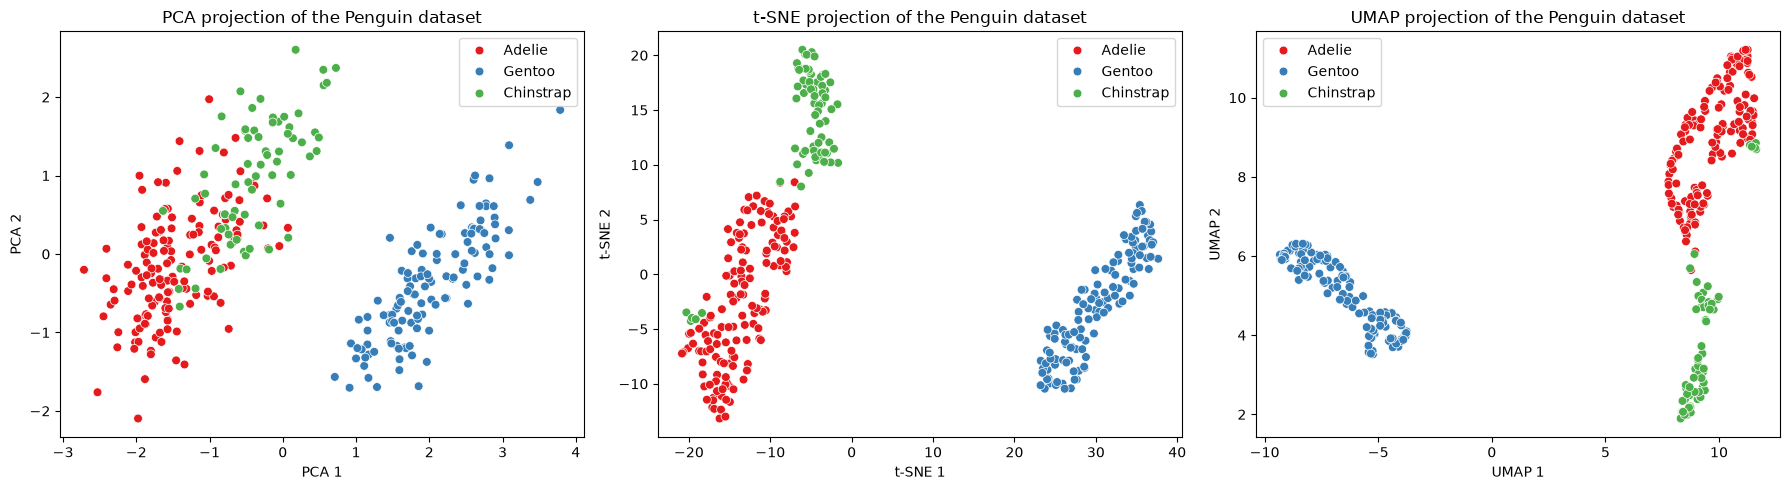

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, emb) in zip(axes, embeddings.items()):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=penguins["species"].values,
                    palette="Set1", s=40, ax=ax)
    ax.set_title(f"{name} projection of the Penguin dataset")
    ax.set_xlabel(f"{name} 1")
    ax.set_ylabel(f"{name} 2")
plt.tight_layout()
plt.show()

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


YOUR TEXT HERE

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

In [ ]:
# YOUR CODE HERE

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

YOUR TEXT HERE

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

In [3]:
import os
print(os.getcwd())
print(os.listdir())


/Users/bzcruz/Braden/School/ds-machine-learning/lab03
['03-tsne-and-umap.ipynb', 'population_labels_lab3.txt', 'genome_data_lab3.npy', '.git']


In [21]:
%pip install matplotlib seaborn scikit-learn umap-learn -q

Note: you may need to restart the kernel to use updated packages.


## 1. Load Data + Imports

In [ ]:
# Imports & Data load

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap.umap_ as umap
from sklearn.decomposition import PCA

# Define file paths
genotypes = 'genome_data_lab3.npy'
labels = 'population_labels_lab3.txt'

# Load data
genotypes = np.load(genotypes)
with open(labels, 'r') as f:
    labels = [line.strip() for line in f.readlines()]

# Print diagnostic info
print(f'Genotype shape: {genotypes.shape}')
print(f'Number of individuals (labels): {len(labels)}')
print(f'Unique population groups: {set(labels)}')
print(f'Number of unique groups: {len(set(labels))}')

Genotype shape: (3450, 868)
Number of individuals (labels): 3450
Unique population groups: {'STU', 'PUR', 'MXL', 'GWD', 'MSL', 'BEB', 'IBS', 'ESN', 'ITU', 'CEU', 'YRI', 'PEL', 'GBR', 'PJL', 'JPT', 'LWK', 'CLM', 'GIH', 'ACB', 'TSI', 'FIN', 'CDX', 'ASW', 'CHB', 'KHV', 'CHS'}
Number of unique groups: 26


## 2. Scale Features

In [23]:
# Standardize the genotype features (zero mean, unit variance)
scaler = StandardScaler()
genotypes_scaled = scaler.fit_transform(genotypes)

print(f"Scaled genotypes shape: {genotypes_scaled.shape}")
print(f"Mean of first 5 features: {genotypes_scaled.mean(axis=0)[:5]}")
print(f"Standard deviation of first 5 features: {genotypes_scaled.std(axis=0)[:5]}")

Scaled genotypes shape: (3450, 868)
Mean of first 5 features: [ 1.23572650e-16  0.00000000e+00  1.64763533e-17  8.23817665e-17
 -4.11908832e-18]
Standard deviation of first 5 features: [1. 1. 1. 1. 1.]


## 3. Apply PCA, t-SNE, UMAP

In [ ]:
# 1. PCA
print("Running PCA ")
pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(genotypes_scaled)

# 2. t-SNE
print("Running t-SNE ")
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(genotypes_scaled)

# 3. UMAP
print("Running UMAP ")
umap_reducer = umap.UMAP(n_components=2, random_state=42)
umap_results = umap_reducer.fit_transform(genotypes_scaled)

print("Dimensionality reduction completed")

Note: you may need to restart the kernel to use updated packages.
Running PCA: 
Running t-SNE: 
Running UMAP: 


/Users/bzcruz/Braden/School/ds-machine-learning/knowledge-check/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Dimensionality reduction completed


## 4. Scatterplots

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE